# Lesson 4 — Rotate a Spot and Unpack Its Covariance Matrix

[Course plan and setup](../../README.md) · [Previous lesson](lesson-03.ipynb) · [Русский](../ru/lesson-04.ipynb) · [Next: several spots](lesson-05.ipynb)

In the previous lesson, we stretched a circle into an ellipse. Its long side always stayed along one of the coordinate axes, though. What if we want to draw a sloping branch or the edge of a roof?

Let's rotate the spot. In the viewer, one slider does the job. Beside it, four numbers appear inside square brackets: the **covariance matrix**. We'll connect those numbers to size and tilt, then use them to calculate the weight at a point.

We won't start with a finished matrix formula. First we'll look at the rotation, then perform it with ordinary multiplication and addition. The matrix will become a short way to write operations we already understand.

This lesson has more moving parts than the previous one: sine, cosine, and matrix multiplication are new here. If you want to split it into two sessions, section 7 is a useful stopping point. By then, you'll already be calculating weights by rotating a point back.

## 1. First, Rotate the Ellipse

Run the cells from top to bottom. As before, GitHub shows saved figures, while the sliders work in Jupyter.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import math
import numpy as np
from IPython.display import display

course_root = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / "gaussian_math.py").is_file()),
    None,
)
if course_root is None:
    raise FileNotFoundError("Open this notebook inside the downloaded course folder.")
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from gaussian_math import gaussian2d, covariance_matrix, inverse_covariance
from covariance_demos import (
    covariance_figure, covariance_lab, rotation_figure,
    sample_covariance_figure, inverse_figure,
)
LANG = 'en'

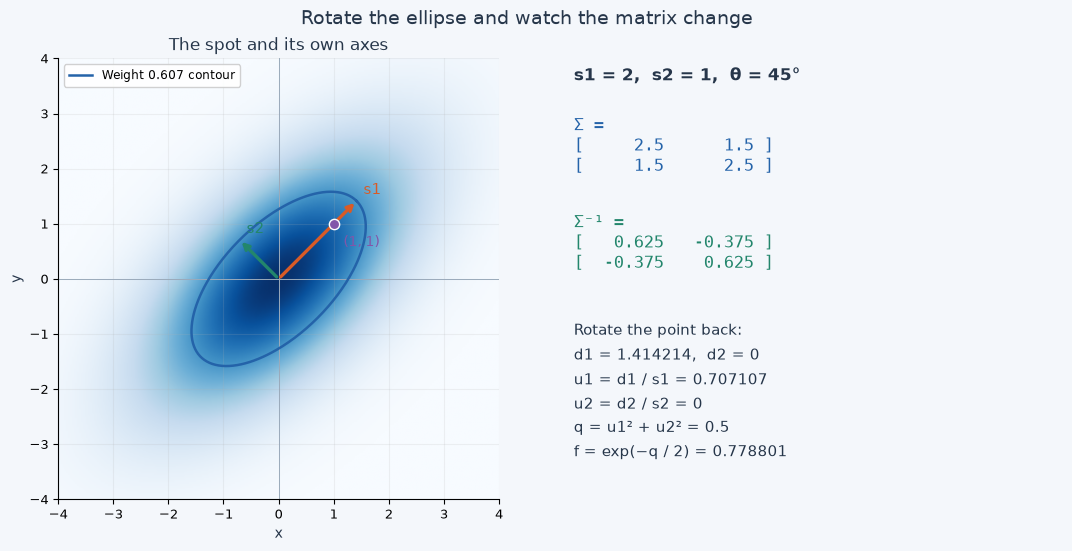

In [2]:
display(covariance_figure(language=LANG))

In [3]:
display(covariance_lab(language=LANG))

Start with the main example: **scales 2 and 1, angle 45°, point (1, 1)**. The center stays at `(0, 0)` throughout this lesson so that translation doesn't distract us from shape.

1. Set the angle to 0°, then 45°, then −45°. The spot keeps its length and thickness. Watch the entries away from the matrix diagonal appear and change sign.
2. Return to 45° and change only the first scale. The spot stretches along its own tilted axis, rather than straight to the right.
3. Choose the “Circle” example and change the angle again. The shape stays the same. A circle has no preferred long direction.
4. Restore the main example and keep the point `(1, 1)` fixed. Depending on the tilt, it lies along the long side or closer to the short side. Its weight changes accordingly.
5. Choose “Point at the center.” The weight becomes 1 for every positive pair of scales and every angle.

The orange and green arrows show the **spot's own axes**. We'll call the scales along them $s_1$ and $s_2$, read “s one” and “s two.” The subscripts simply distinguish the two axes. Initially, $s_1=2$ and $s_2=1$.

After rotation, these axes no longer match world $x$ and $y$. So we won't call $s_1$ the “width along x”: it is the scale along the first, tilted axis.

The blue line joins points with weight $e^{-1/2}\approx0.607$. As in lesson 3, the spot continues beyond it. Here the line helps us compare shapes.

## 2. Why the Matrix Stores Squared Sizes

Recall the axis-aligned ellipse from lesson 3. For offsets $d_x$ and $d_y$, we calculated:

$$
q=\left(\frac{d_x}{s_1}\right)^2+\left(\frac{d_y}{s_2}\right)^2,
\qquad f=\exp(-q/2).
$$

$d_x=x-\mu_x$ and $d_y=y-\mu_y$ tell us how far the point is displaced from the center in each direction. $\mu_x,\mu_y$ are the center coordinates. For now, both are zero, so $d_x=x$ and $d_y=y$.

Squaring the fractions puts $s_1^2$ and $s_2^2$ in their denominators. With scales 2 and 1, these are $2\cdot2=4$ and $1\cdot1=1$. Those squares will form the diagonal of the unrotated spot's matrix.

Why are they called **variances**? Take a small collection of numbers: −2, −2, 2, 2. Their mean is:

$$
\bar x=\frac{-2-2+2+2}{4}=0.
$$

The bar over $x$ means “mean x.” Subtract the mean from each number, square each difference, and take their average:

$$
v_x=\frac{(-2-0)^2+(-2-0)^2+(2-0)^2+(2-0)^2}{4}
=\frac{4+4+4+4}{4}=4.
$$

This is the **variance**: the mean squared deviation from the mean. It measures spread, but in squared units. If the coordinates are centimeters, the variance is 4 cm². Taking the square root returns us to centimeters: $\sqrt4=2$ cm. This is the **standard deviation**.

For a Gaussian, the scale $s$ is defined so that $s^2$ is the variance of the normalized distribution with that shape. We're still drawing an unnormalized weight with a peak of 1; we don't need the probability-density prefactor here.

The four numbers above let us see the arithmetic of spread. They do not become a Gaussian, nor are they required points of one. We choose our spot's scales ourselves.

## 3. Covariance: Do the Two Coordinates Change Together?

Now take four points on a plane:

| Point | x | y | x² | x·y | y² |
|---|---:|---:|---:|---:|---:|
| A | −2 | −1 | 4 | 2 | 1 |
| B | −2 | 1 | 4 | −2 | 1 |
| C | 2 | −1 | 4 | −2 | 1 |
| D | 2 | 1 | 4 | 2 | 1 |
| Mean | 0 | 0 | 4 | 0 | 1 |

Both mean coordinates are zero, so deviations from the mean equal $x$ and $y$ themselves.

The $x^2$ and $y^2$ columns give variances 4 and 1. The $x\cdot y$ column asks a different question: **do the two coordinate deviations have matching signs?** Two positive or two negative deviations give a positive product. Opposite signs give a negative product.

The average of those products is the **covariance**:

$$
b=\frac{2-2-2+2}{4}=0.
$$

The positive and negative contributions cancel. This set favors neither an “up and right” nor a “down and right” tilt.

If the set is not centered at zero, first subtract its means. In general:

$$
b=\frac1N\sum_{i=1}^{N}(x_i-\bar x)(y_i-\bar y).
$$

Here $N$ is the number of points; $i$ is the current point's index; $x_i,y_i$ are its coordinates; and $\sum$ (“sigma”) says “add the results for every index from 1 to N.” For each point, subtract the means, multiply the two deviations, add all the products, and divide by the number of points.

We are describing **the entire given set**, so we divide by $N=4$. When estimating an unknown covariance from a random sample, statistics often uses $N-1$. That is a different task; we must not switch divisors halfway through this example.

Covariance also has units of cm² if both coordinates use centimeters. It is not an angle in degrees. Its relation to tilt also involves the two variances: the single number $b$ does not determine the whole ellipse.

## 4. Four Numbers Instead of Three Long Labels

Put the numbers into a table with two rows and two columns:

$$
\Sigma=
\begin{bmatrix}
v_x & b\\
b & v_y
\end{bmatrix}
=\begin{bmatrix}4&0\\0&1\end{bmatrix}.
$$

Capital $\Sigma$ is read “sigma.” Here it names the entire matrix, unlike the small $\sigma$ from lesson 2. A matrix is a rectangular array of numbers; below, we'll define how to perform operations with it.

- The upper-left entry is variance along world $x$.
- The lower-right entry is variance along world $y$.
- The remaining entries are covariance. They match because $x\cdot y$ and $y\cdot x$ give the same product.

The line from the upper-left entry to the lower-right one is the **main diagonal**. A matrix whose entries match across this diagonal is **symmetric**.

For our unrotated spot:

$$
D=\begin{bmatrix}s_1^2&0\\0&s_2^2\end{bmatrix}
=\begin{bmatrix}4&0\\0&1\end{bmatrix}.
$$

We'll reserve $D$ for the matrix in the spot's own axes. In $\mathrm{diag}(4,1)$, `diag` simply means “put 4 and 1 on the diagonal and fill the remaining entries with zeros.”

While the spot's axes match $x,y$, $D$ and $\Sigma$ are identical. After rotation, $D$ keeps its 4 and 1, while $\Sigma$, the shape written in world coordinates, changes.

## 5. Rotation Before Matrices: Two Projections of an Arrow

Draw an arrow of length 1, initially pointing right. Its tip is at `(1, 0)`. Rotate it counterclockwise through an angle $\theta$, read “theta.”

A full turn is 360°, and a quarter turn is 90°. At 45°, the arrow points halfway between right and up.

After rotation, its tip has coordinates:

$$
(\cos\theta,\ \sin\theta).
$$

**Cosine** is the horizontal coordinate of the unit arrow's tip; **sine** is its vertical coordinate. These are signed projections: the horizontal coordinate is negative on the left, and the vertical coordinate is negative below zero.

| Angle | cos θ | sin θ | Direction of the first axis |
|---|---:|---:|---|
| 0° | 1 | 0 | Right |
| 90° | 0 | 1 | Up |
| 180° | −1 | 0 | Left |
| −90° | 0 | −1 | Down |

At 45°, the two projections match. For a right triangle, the square of the sloping side's length equals the sum of the squares of the other two sides. Our arrow has length 1, so $c^2+c^2=1$: first $2c^2=1$, then $c^2=1/2$, then $c=1/\sqrt2\approx0.707107$. We take the positive root because the arrow points up and right. Thus $\cos45°=\sin45°=1/\sqrt2$.

Below we'll shorten the notation to $c=\cos\theta$ and $s=\sin\theta$. Here $s$ **without a subscript** means sine; the spot's scales are still $s_1,s_2$.

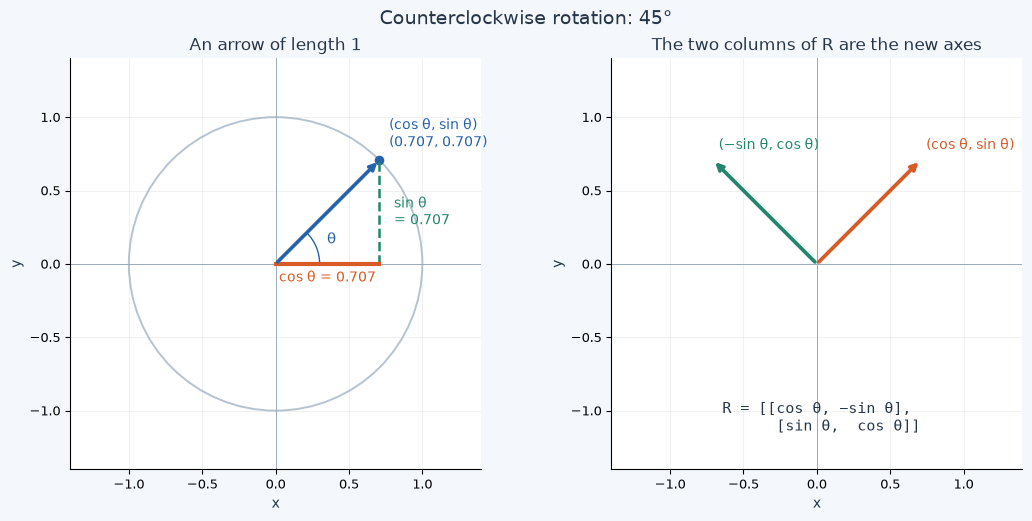

In [4]:
display(rotation_figure(angle_deg=45, language=LANG))

The second axis must be perpendicular to the first. If the first points along $(c,s)$, the second points along $(-s,c)$. At 45° this is `(-0.707107, 0.707107)`, up and left. Both arrows have length 1.

Suppose a point lies $a$ units along the first axis and $b$ units along the second. Here $a,b$ are the point's coordinates in the spot's frame; we'll set aside the covariance symbol $b$ for a moment. Add the two displacements:

$$
\begin{aligned}
x&=ca-sb,\\
y&=sa+cb.
\end{aligned}
$$

For example, $(a,b)=(2,0)$ at 45° gives $x=0.707107\cdot2-0.707107\cdot0\approx1.414214$ and $y=0.707107\cdot2+0.707107\cdot0\approx1.414214$.

The numbers 2 and 0 have not changed as coordinates along the spot's own axes. We've worked out where that same point lies in world coordinates.

## 6. Write the Same Rotation as a Matrix

Put the coefficients of our two operations into a table:

$$
R=\begin{bmatrix}c&-s\\s&c\end{bmatrix},
\qquad
\begin{bmatrix}x\\y\end{bmatrix}
=R\begin{bmatrix}a\\b\end{bmatrix}.
$$

$R$ names the rotation matrix. Two numbers written vertically form a **column vector**. Here it simply stores two coordinates.

Matrix–vector multiplication works **row against column**. For the first output coordinate, multiply each entry of the first row by the matching entry of the column and add: $c\cdot a+(-s)\cdot b$. For the second, use the second row: $s\cdot a+c\cdot b$. This performs exactly the geometric operation from the previous section.

The columns of $R$ have a meaning too: the first tells us where the unit arrow `(1,0)` went, and the second tells us where `(0,1)` went.

Python's `@` operator performs this matrix multiplication. Ordinary `*` between NumPy arrays multiplies matching entries, so it cannot replace `@` here.

`math.sin` and `math.cos` take angles **in radians**. One radian is an angle whose arc on a circle of radius 1 has length 1. A full circle has arc length $2\pi$, so 360° is $2\pi$ radians. Thus 180° is $\pi$, and 45° is $\pi/4\approx0.785398$. The number $\pi\approx3.141593$ is a circle's circumference divided by its diameter. `math.radians` handles the conversion for us.

In [5]:
theta_deg = 45.0
theta_rad = math.radians(theta_deg)
c = math.cos(theta_rad)
s = math.sin(theta_rad)
R = np.array([[c, -s], [s, c]])
local_point = np.array([2.0, 0.0])
world_point = R @ local_point
print("angle in radians =", round(theta_rad, 6))
print("cos, sin =", round(c, 6), round(s, 6))
print("R =\n", np.round(R, 6))
print("world point =", np.round(world_point, 6))

angle in radians = 0.785398
cos, sin = 0.707107 0.707107
R =
 [[ 0.707107 -0.707107]
 [ 0.707107  0.707107]]
world point = [1.414214 1.414214]


## 7. To Calculate the Weight, Rotate the Point Back

We can now turn coordinates along the spot's axes into world coordinates. But the viewer gives us a world point. To use the formula from lesson 3, we need its offsets **along the ellipse's own axes**.

First subtract the center, then rotate that offset through **the negative of the same angle**. For a rotation matrix, its transpose does this:

$$
R^T=\begin{bmatrix}c&s\\-s&c\end{bmatrix}.
$$

The superscript $T$ means “transpose,” not a power. Rows become columns: the upper-right and lower-left entries exchange places. For a rotation matrix, this gives the reverse rotation; for an arbitrary matrix, transposing does not replace taking the inverse.

Write the world offset as a column $d$, and call its coordinates after the reverse rotation $d_1,d_2$:

$$
d=\begin{bmatrix}d_x\\d_y\end{bmatrix},
\qquad
\begin{bmatrix}d_1\\d_2\end{bmatrix}
=R^Td
=\begin{bmatrix}cd_x+sd_y\\-sd_x+cd_y\end{bmatrix}.
$$

Calculate it for `(1,1)`, center `(0,0)`, and angle 45°. We'll use the exact values $c=s=1/\sqrt2$ and round only for display:

$$
\begin{aligned}
d_x&=1-0=1,\qquad d_y=1-0=1,\\
d_1&=\frac1{\sqrt2}\cdot1+\frac1{\sqrt2}\cdot1=\sqrt2\approx1.414214,\\
d_2&=-\frac1{\sqrt2}\cdot1+\frac1{\sqrt2}\cdot1=0.
\end{aligned}
$$

The point lies entirely along the first, long axis. Divide that coordinate by scale 2 and the second coordinate by scale 1:

$$
\begin{aligned}
u_1&=d_1/s_1=\sqrt2/2=1/\sqrt2,\\
u_2&=d_2/s_2=0/1=0,\\
q&=u_1^2+u_2^2=1/2+0=0.5,\\
f&=\exp(-0.5/2)=\exp(-0.25)\approx0.778801.
\end{aligned}
$$

The first two divisions measure the offsets in units of their respective scales. The squares remove the signs, the sum combines the directions, and the exponential turns distance into weight. Every operation after the rotation is familiar.

To check the reverse rotation, multiply $R^TR$. The first diagonal entry is $c^2+s^2=1$, and the second is also 1; off the diagonal, $-cs+sc=0$. So rotating and rotating back really do return the original coordinates.

In [6]:
d = np.array([1.0, 1.0])
local = R.T @ d
u = local / np.array([2.0, 1.0])
q_local = u[0] * u[0] + u[1] * u[1]
weight_local = math.exp(-q_local / 2)
print("R.T @ R =\n", np.round(R.T @ R, 6))
print("local offsets =", np.round(local, 6))
print("scaled offsets =", np.round(u, 6))
print("q =", round(q_local, 6))
print("weight =", round(weight_local, 6))

R.T @ R =
 [[ 1. -0.]
 [-0.  1.]]
local offsets = [1.414214 0.      ]
scaled offsets = [0.707107 0.      ]
q = 0.5
weight = 0.778801


## 8. How Rotation Changes the Covariance Matrix

Return to the four shape entries. We need a matrix in world coordinates, even though $s_1,s_2$ are scales along the spot's own axes.

First, see where the transformation rule comes from. Multiply an offset column $d$ by its transposed row:

$$
\begin{bmatrix}d_x\\d_y\end{bmatrix}
\begin{bmatrix}d_x&d_y\end{bmatrix}
=\begin{bmatrix}d_x^2&d_xd_y\\d_yd_x&d_y^2\end{bmatrix}.
$$

Multiplication is still row against column. Each entry has just one pair to multiply: $d_x\cdot d_x$ at the top left, $d_x\cdot d_y$ at the top right, and so on. These are exactly the squares and products we averaged for variance and covariance.

After rotation, each offset becomes $Rd$. Its transposed row becomes $d^TR^T$: the order of the two factors reverses. The product table after rotation is therefore $R(dd^T)R^T$. When we average those tables, the same $R$ applies to every point and can stay outside the average. This gives:

$$
\Sigma=RDR^T.
$$

This is the covariance transformation rule for rotation. For a Gaussian, it describes the same shape using different coordinate axes. The four corner points make the arithmetic visible; they do not replace the Gaussian.

Now expand both multiplications. First multiply $R$ by $D$. For each entry, take a row of the left matrix and a column of the right one:

$$
RD=
\begin{bmatrix}c&-s\\s&c\end{bmatrix}
\begin{bmatrix}s_1^2&0\\0&s_2^2\end{bmatrix}
=\begin{bmatrix}cs_1^2&-ss_2^2\\ss_1^2&cs_2^2\end{bmatrix}.
$$

For example, the upper-left entry is $c\cdot s_1^2+(-s)\cdot0=cs_1^2$. The upper-right one is $c\cdot0+(-s)\cdot s_2^2=-ss_2^2$. The zeros remove one term from each sum. The lower row works the same way.

Now multiply the resulting table by $R^T$. Here are all four entries:

$$
\begin{aligned}
\Sigma_{11}&=(cs_1^2)c+(-ss_2^2)(-s)=c^2s_1^2+s^2s_2^2,\\
\Sigma_{12}&=(cs_1^2)s+(-ss_2^2)c=cs(s_1^2-s_2^2),\\
\Sigma_{21}&=(ss_1^2)c+(cs_2^2)(-s)=cs(s_1^2-s_2^2),\\
\Sigma_{22}&=(ss_1^2)s+(cs_2^2)c=s^2s_1^2+c^2s_2^2.
\end{aligned}
$$

Read the subscripts `11`, `12`, `21`, `22` as “row number, column number,” starting at 1. For example, $\Sigma_{12}$ is the first row, second column. The two off-diagonal entries match, as they should in a covariance matrix.

In the main example, $s_1^2=4$ and $s_2^2=1$. At 45°, $c^2=s^2=cs=1/2$. Substituting:

$$
\begin{aligned}
\Sigma_{11}&=(1/2)\cdot4+(1/2)\cdot1=2+0.5=2.5,\\
\Sigma_{12}&=(1/2)(4-1)=1.5,\\
\Sigma_{21}&=1.5,\\
\Sigma_{22}&=(1/2)\cdot4+(1/2)\cdot1=2.5.
\end{aligned}
$$

We get the matrix from the beginning:

$$
\Sigma=\begin{bmatrix}2.5&1.5\\1.5&2.5\end{bmatrix}.
$$

The diagonal entries 2.5 mean equal variances **along world x and y**. But the spot has not become a circle: the positive 1.5 entries couple these directions and preserve the tilted, elongated shape. Its own scales are still 2 and 1. Its world-coordinate standard deviations are now $\sqrt{2.5}\approx1.581139$.

In [7]:
s1, s2 = 2.0, 1.0
D = np.array([[s1 * s1, 0.0], [0.0, s2 * s2]])
RD = R @ D
Sigma = RD @ R.T
print("D =\n", D)
print("R @ D =\n", np.round(RD, 6))
print("Sigma =\n", np.round(Sigma, 6))

D =
 [[4. 0.]
 [0. 1.]]
R @ D =
 [[ 2.828427 -0.707107]
 [ 2.828427  0.707107]]
Sigma =
 [[2.5 1.5]
 [1.5 2.5]]


## 9. Check the Matrix with the Same Four Points

Rotate our rectangular point set. Point A started at `(−2,−1)`. After a 45° rotation:

$$
\begin{aligned}
x_A&=-2/\sqrt2+1/\sqrt2=-1/\sqrt2\approx-0.707107,\\
y_A&=-2/\sqrt2-1/\sqrt2=-3/\sqrt2\approx-2.121320.
\end{aligned}
$$

Its squared coordinates are $x_A^2=1/2=0.5$ and $y_A^2=9/2=4.5$, while its product is $x_Ay_A=3/2=1.5$. Two negative coordinates give a positive covariance contribution.

The figure calculates the other points too. Displayed values are rounded; the calculation uses the original numbers.

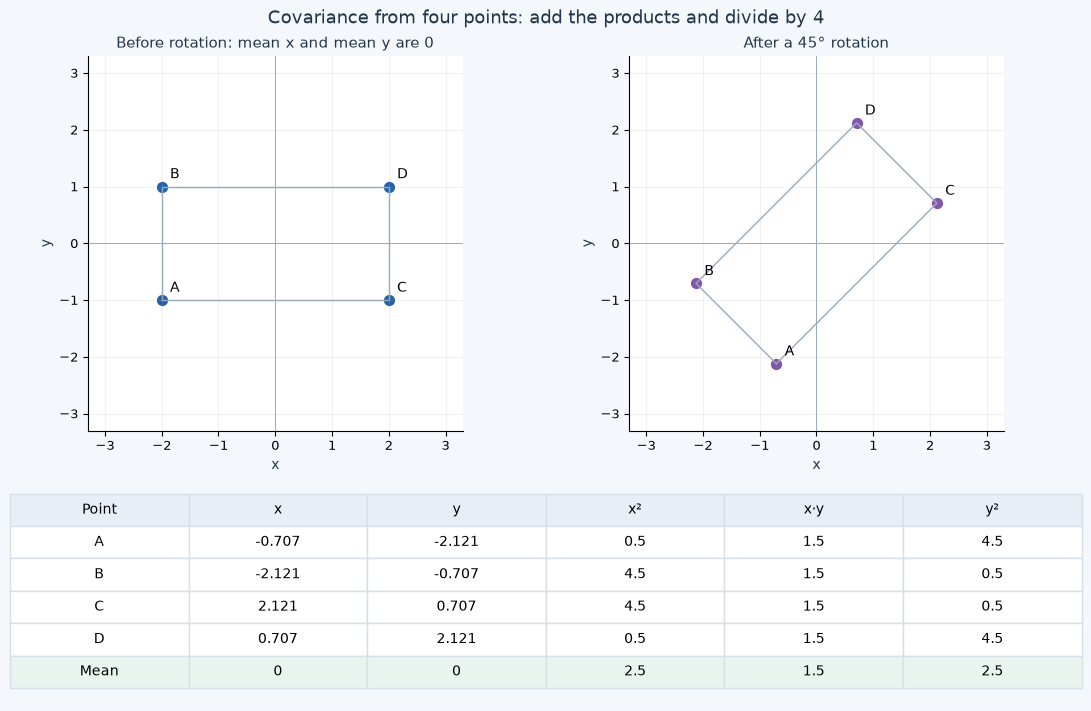

In [8]:
display(sample_covariance_figure(angle_deg=45, language=LANG))

The mean coordinates are still zero. Average the squares and products:

$$
\begin{aligned}
v_x&=(0.5+4.5+4.5+0.5)/4=10/4=2.5,\\
b&=(1.5+1.5+1.5+1.5)/4=6/4=1.5,\\
v_y&=(4.5+0.5+0.5+4.5)/4=10/4=2.5.
\end{aligned}
$$

These are the same entries as in $RDR^T$. Rotating the original rectangle by −45° instead keeps the diagonal entries at 2.5 and makes the other two −1.5. With equal variances, the covariance sign distinguishes the two tilt directions.

Zero covariance does not mean two quantities have no relationship at all: it measures the average product of their deviations. Here we care about Gaussian geometry, where the covariance matrix and center specify the shape of the weight.

## 10. Why We Need an Inverse Matrix

Ordinary squared distance grows as we move away from the center. But equal steps along the long and short sides should give different weights. In lesson 3, we handled that by dividing by the scales.

The shape matrix stores **squared** scales. To calculate a squared distance, we therefore need their reciprocals: $1/4$ instead of 4, and $1/1$ instead of 1. For a rotated spot, the **inverse matrix** $\Sigma^{-1}$ does this job, read “sigma inverse.”

This does not mean “replace every entry by its reciprocal.” The inverse has a different definition: multiplying it by the original matrix must give the **identity matrix**:

$$
I=\begin{bmatrix}1&0\\0&1\end{bmatrix},
\qquad
\Sigma\Sigma^{-1}=I.
$$

Try $I$ on a column: the first row gives $1\cdot x+0\cdot y=x$, and the second gives $0\cdot x+1\cdot y=y$. It leaves the coordinates unchanged.

For a general symmetric table, temporarily name its three distinct entries $A,B,C$:

$$
\Sigma=\begin{bmatrix}A&B\\B&C\end{bmatrix}.
$$

Here $A$ is the upper-left entry, $C$ is the lower-right one, and $B$ fills both off-diagonal entries. These are not the scales $s_1,s_2$. In our example, $A=C=2.5$ and $B=1.5$.

First calculate the **determinant**:

$$
\Delta=AC-B^2.
$$

$\Delta$ is read “delta.” For a 2×2 table, multiply the entries on the main diagonal and subtract the product on the other diagonal. For a symmetric matrix, the second product is $B\cdot B=B^2$.

Why does this number appear when finding an inverse? Exchange the diagonal entries, negate the other two, and multiply:

$$
\begin{aligned}
\begin{bmatrix}A&B\\B&C\end{bmatrix}
\begin{bmatrix}C&-B\\-B&A\end{bmatrix}
&=\begin{bmatrix}AC-B^2&-AB+BA\\BC-CB&-B^2+CA\end{bmatrix}\\
&=\begin{bmatrix}\Delta&0\\0&\Delta\end{bmatrix}.
\end{aligned}
$$

Each entry is expanded as row against column. Both off-diagonal results cancel to zero. If $\Delta\ne0$, divide every entry of the second matrix by $\Delta$, and the result will have ones on its diagonal:

$$
\Sigma^{-1}=\frac1\Delta
\begin{bmatrix}C&-B\\-B&A\end{bmatrix}.
$$

That's the inverse formula. It is not a separate trick to memorize: we just checked how it undoes the original multiplication.

## 11. Work Out the Inverse for Our Spot

Substitute the numbers:

$$
\Delta=2.5\cdot2.5-1.5\cdot1.5=6.25-2.25=4.
$$

Now exchange the diagonal entries, negate the other two, and divide everything by 4:

$$
\begin{aligned}
\Sigma^{-1}
&=\frac14\begin{bmatrix}2.5&-1.5\\-1.5&2.5\end{bmatrix}\\
&=\begin{bmatrix}2.5/4&-1.5/4\\-1.5/4&2.5/4\end{bmatrix}\\
&=\begin{bmatrix}0.625&-0.375\\-0.375&0.625\end{bmatrix}.
\end{aligned}
$$

Check two entries of $\Sigma\Sigma^{-1}$:

$$
\begin{aligned}
(\Sigma\Sigma^{-1})_{11}
&=2.5\cdot0.625+1.5\cdot(-0.375)\\
&=1.5625-0.5625=1,\\
(\Sigma\Sigma^{-1})_{12}
&=2.5\cdot(-0.375)+1.5\cdot0.625\\
&=-0.9375+0.9375=0.
\end{aligned}
$$

The lower row gives 0 and 1. We have indeed obtained $I$.

If coordinates use centimeters, the entries of $\Sigma$ have units cm². A determinant multiplies two such quantities, giving cm⁴. Dividing the entries by it gives cm² / cm⁴ = 1/cm² for $\Sigma^{-1}$. Below, those units will cancel against two offsets.

Code indices start at **0**: the mathematical entry $\Sigma_{11}$ is `Sigma[0, 0]`. The first index selects the row; the second selects the column.

In [9]:
A = Sigma[0, 0]
B = Sigma[0, 1]
C = Sigma[1, 1]
determinant = A * C - B * B
inverse_manual = np.array([[C, -B], [-B, A]]) / determinant
print("A*C - B*B =", round(determinant, 6))
print("inverse =\n", np.round(inverse_manual, 6))
print("Sigma @ inverse =\n", np.round(Sigma @ inverse_manual, 6))

A*C - B*B = 4.0
inverse =
 [[ 0.625 -0.375]
 [-0.375  0.625]]
Sigma @ inverse =
 [[1. 0.]
 [0. 1.]]


## 12. Read dᵀΣ⁻¹d and Get One Number

We're ready for the compact Gaussian formula:

$$
f(x,y)=\exp\left(-\frac12d^T\Sigma^{-1}d\right),
\qquad
d=\begin{bmatrix}x-\mu_x\\y-\mu_y\end{bmatrix}.
$$

Read it **from the inside out**:

1. Subtract the center to obtain the two-offset column $d$.
2. Multiply $\Sigma^{-1}$ by $d$ to obtain a new column of two numbers.
3. Multiply that column on the left by the row $d^T$: add two products to obtain one number, $q$.
4. Divide $q$ by 2, negate it, and calculate the exponential.

The whole expression $d^T\Sigma^{-1}d$ replaces the familiar sum of squared normalized offsets. It is called a **quadratic form** because the offset participates twice. The name describes the expression; it doesn't add another operation.

For `(1,1)`, both offsets are 1. First multiply the matrix by the column:

$$
v=\Sigma^{-1}d
=\begin{bmatrix}0.625&-0.375\\-0.375&0.625\end{bmatrix}
\begin{bmatrix}1\\1\end{bmatrix}
=\begin{bmatrix}0.625-0.375\\-0.375+0.625\end{bmatrix}
=\begin{bmatrix}0.25\\0.25\end{bmatrix}.
$$

$v$ is a temporary name for that column. Now multiply it by the original offset written as a row:

$$
q=d^Tv
=\begin{bmatrix}1&1\end{bmatrix}\begin{bmatrix}0.25\\0.25\end{bmatrix}
=1\cdot0.25+1\cdot0.25=0.5.
$$

The last two operations are:

$$
-q/2=-0.5/2=-0.25,
\qquad f(1,1)=\exp(-0.25)\approx0.778801.
$$

This is the same weight we found by rotating the point back. The matrix combines the handling of tilt and scale into one table.

The units work too: an offset in cm, an inverse matrix in 1/cm², and another offset in cm give cm × 1/cm² × cm = 1. So $q$ is dimensionless, just like the exponent.

In [10]:
offset = np.array([1.0, 1.0])
v = inverse_manual @ offset
q_matrix = offset @ v
weight_matrix = math.exp(-q_matrix / 2)
weight_direct = gaussian2d(1, 1, sx=2, sy=1, angle_deg=45)
print("inverse @ offset =", np.round(v, 6))
print("offset @ v =", round(float(q_matrix), 6))
print("matrix weight =", round(weight_matrix, 6))
print("local-coordinate weight =", round(weight_local, 6))
print("demo weight =", round(float(weight_direct), 6))

inverse @ offset = [0.25 0.25]
offset @ v = 0.5
matrix weight = 0.778801
local-coordinate weight = 0.778801
demo weight = 0.778801


The next figure shows the same calculation geometrically. We rotate the coordinates back, then divide them by the scales. The weight-0.607 contour becomes a circle of radius 1. In that final coordinate system, the ordinary sum of squared coordinates gives the required $q$.

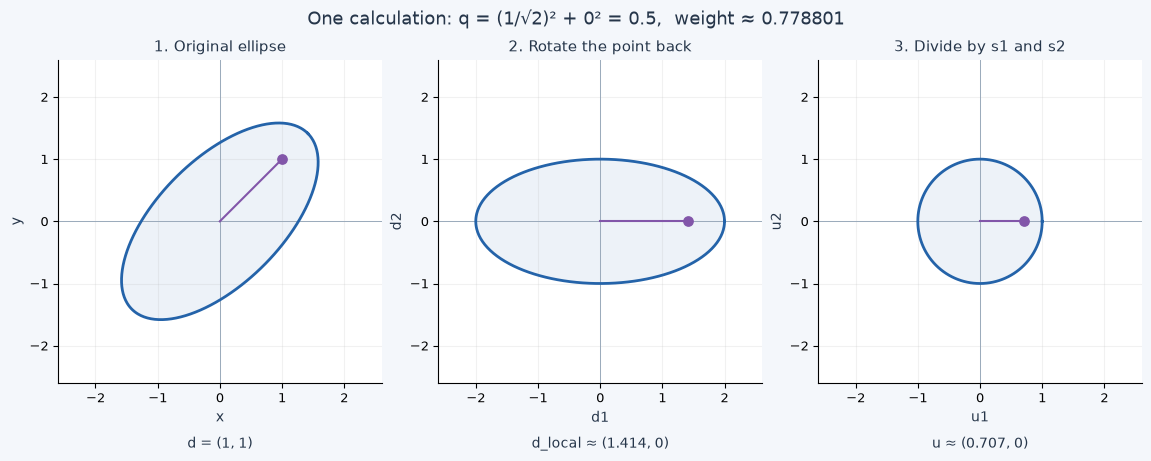

In [11]:
display(inverse_figure(language=LANG))

## 13. Which Numbers Cannot Describe Our Shape?

$q$ must be positive for every nonzero offset. Then the weight is 1 at the center and decreases away from it. A matrix with this property is called **positive definite**. For our Gaussian, both $\Sigma$ and its inverse are positive definite.

For a symmetric 2×2 matrix, two conditions test this:

$$
A>0,\qquad \Delta=AC-B^2>0.
$$

The first requires positive spread along the first world axis. The second prevents covariance from becoming so large that an independent width vanishes or the squared-distance value becomes negative.

<details>
<summary>Why these two conditions are enough: expand the squares</summary>

The inverse formula gives, for any offset:

$$
q=\frac{Cd_x^2-2Bd_xd_y+Ad_y^2}{\Delta}.
$$

The cross-product occurs twice, once from each row. That is why it has a factor of 2.

The same result can be written as a sum of two squares:

$$
q=\frac{d_x^2}{A}+\frac{A}{\Delta}\left(d_y-\frac{B}{A}d_x\right)^2.
$$

Check it: expanding the second square gives $Ad_y^2/\Delta-2Bd_xd_y/\Delta+B^2d_x^2/(A\Delta)$. Add $d_x^2/A$; the total coefficient of $d_x^2$ is $(\Delta+B^2)/(A\Delta)=AC/(A\Delta)=C/\Delta$. We have recovered the original expression.

If $A>0$ and $\Delta>0$, both square coefficients are positive. When $d_x\ne0$, the first term is positive. When $d_x=0$ but $d_y\ne0$, the second is positive. Every nonzero offset therefore gives $q>0$.

</details>

Consider three cases:

| Matrix | Determinant | What happened |
|---|---:|---|
| `[[2.5, 1.5], [1.5, 2.5]]` | 4 | Two positive widths; the weight calculation works |
| `[[1, 1], [1, 1]]` | 0 | One width has collapsed; there is no ordinary inverse |
| `[[1, 2], [2, 1]]` | −3 | Invertible, but it does not describe the Gaussian we need |

In the second case, covariance can correctly describe points lying on a line. Our nondegenerate two-dimensional Gaussian, however, needs a positive width in every direction. Otherwise the formula using an ordinary inverse does not apply.

In the third case, the inverse is `[[-1/3, 2/3], [2/3, -1/3]]`. For offset `(1,−1)`, it gives the column `(−1,1)`, then $q=1\cdot(-1)+(-1)\cdot1=-2$. The weight becomes $\exp(-(-2)/2)=e^1\approx2.71828$, higher than the peak. The determinant sign warned us about this failure.

That's why the sliders control positive $s_1,s_2$ and an angle, then build the matrix from them. It keeps the shape valid more easily than adjusting all the matrix entries independently.

The next cell catches errors with `try/except`, so invalid examples do not stop the notebook. This checks input; it does not try to draw a zero-width Gaussian.

In [12]:
examples = [
    np.array([[2.5, 1.5], [1.5, 2.5]]),
    np.array([[1.0, 1.0], [1.0, 1.0]]),
    np.array([[1.0, 2.0], [2.0, 1.0]]),
]
for matrix in examples:
    print(matrix.tolist())
    try:
        valid_inverse = inverse_covariance(matrix)
        print("Можно считать вес" if LANG == "ru" else "Valid for the weight calculation")
        print(np.round(valid_inverse, 6))
    except ValueError:
        print("Матрица формы не подходит" if LANG == "ru" else "Not a valid shape matrix")

[[2.5, 1.5], [1.5, 2.5]]
Valid for the weight calculation
[[ 0.625 -0.375]
 [-0.375  0.625]]
[[1.0, 1.0], [1.0, 1.0]]
Not a valid shape matrix
[[1.0, 2.0], [2.0, 1.0]]
Not a valid shape matrix


## 14. Back to the Sliders

The table beside the ellipse should now be easier to read. It stores squared spread along the world directions and the coupling between them. The inverse tells us how to account for that shape when calculating a weight.

Try three experiments. Before each one, restore the main example: $s_1=2$, $s_2=1$, point `(1,1)`.

| What to change | What to predict first |
|---|---|
| Angle 45° → 0° | What matrix will appear, and why will the weight decrease? |
| Angle 45° → −45° | Which entries change sign? Along which axis will the point lie? |
| Set both scales to 2 | What happens to the matrix's and weight's dependence on angle? |

<details>
<summary>Numbers to compare</summary>

**0°.** The matrix is $\Sigma=\mathrm{diag}(4,1)$, and its inverse is $\mathrm{diag}(1/4,1)$. For `(1,1)`, $q=1^2/4+1^2/1=0.25+1=1.25$, the exponent is $-1.25/2=-0.625$, and the weight is $\exp(-0.625)\approx0.535261$.

**−45°.** The matrix is `[[2.5,−1.5],[−1.5,2.5]]`. Rotating back gives $d_1=(1-1)/\sqrt2=0$ and $d_2=(1+1)/\sqrt2=\sqrt2$. Dividing by the scales gives $u_1=0/2=0$ and $u_2=\sqrt2/1=\sqrt2$. Thus $q=0+2=2$, the exponent is −1, and the weight is $e^{-1}\approx0.367879$. The same world point now lies along the short side.

**Both scales 2.** Each diagonal entry is $4c^2+4s^2=4(c^2+s^2)=4$. Off the diagonal, $cs(4-4)=0$. Thus $\Sigma=4I$ for every angle. At `(1,1)`, $q=1/4+1/4=0.5$, giving a weight of about 0.778801. Matching the original example at one point does not make the whole shape identical: this is a circle, while the original is an ellipse.

</details>

A 180° turn also leaves the spot's shape unchanged. Compare 45° and −135° with the slider. Both local arrows reverse direction, but the squares of the local coordinates stay the same.

A very small positive scale is mathematically allowed, but makes reciprocal values very large. Calculations then become more sensitive to rounding. The sliders' lower bound of 0.25 keeps the experiment convenient; it is not a universal minimum Gaussian scale.

## 15. A Few Problems, Worked All the Way Through

### Problem 1. Why Doesn't an Equal Diagonal Guarantee a Circle?

Compare `[[2.5,1.5],[1.5,2.5]]` and `[[2.5,0],[0,2.5]]`. Their diagonals match. How do their spots differ?

<details>
<summary>Worked answer</summary>

The first has scales 2 and 1 at 45°: it is our ellipse. The second has no coupling between directions, and its two scales match: $\sqrt{2.5}$ and $\sqrt{2.5}$. It is therefore a circle.

Look at `(1,1)`. For the first matrix, we already found $q=0.5$ and weight about 0.778801. For the second, each inverse diagonal entry is $1/2.5=0.4$, so $q=0.4\cdot1^2+0.4\cdot1^2=0.8$, the exponent is −0.4, and the weight is $e^{-0.4}\approx0.670320$. Matching diagonal entries still gave different weights.

</details>

### Problem 2. Calculate `(2,0)` in Two Ways

Use the main matrix `[[2.5,1.5],[1.5,2.5]]` and center `(0,0)`. First use the inverse matrix; then rotate back and divide by the scales.

<details>
<summary>Worked answer</summary>

Using the matrix: $v_x=0.625\cdot2-0.375\cdot0=1.25$ and $v_y=-0.375\cdot2+0.625\cdot0=-0.75$. Then $q=2\cdot1.25+0\cdot(-0.75)=2.5$. The exponent is −1.25, and the weight is $e^{-1.25}\approx0.286505$.

Using rotation: $d_1=2/\sqrt2=\sqrt2$ and $d_2=-2/\sqrt2=-\sqrt2$. Dividing gives $u_1=\sqrt2/2=1/\sqrt2$ and $u_2=-\sqrt2/1=-\sqrt2$. Squaring gives $u_1^2=1/2$ and $u_2^2=2$. Their sum is $q=0.5+2=2.5$, the same result. A negative second coordinate did not produce a negative weight.

</details>

### Problem 3. Why Can't We Just Take Every Entry's Reciprocal?

Try “one divided by every entry” on `[[4,0],[0,1]]`. Where does it fail, and what is the actual inverse?

<details>
<summary>Worked answer</summary>

The off-diagonal entries would require division by zero. Yet the matrix is valid: its determinant is $4\cdot1-0\cdot0=4$. The inverse formula gives $\frac14\begin{bmatrix}1&0\\0&4\end{bmatrix}=\begin{bmatrix}0.25&0\\0&1\end{bmatrix}$. The two nonzero diagonal scales are inverted, while the zeros stay zero. Nonzero off-diagonal entries require the general formula, not element-by-element reciprocals.

</details>

### Problem 4. Change Centimeters to Meters

Point `(1,1)` cm and scales 2 cm and 1 cm are given at 45°. If we convert every coordinate and scale to meters, should the weight change?

<details>
<summary>Worked answer</summary>

Every length is now written as a number 100 times smaller: point `(0.01,0.01)`, scales 0.02 and 0.01. In the local calculation, both the offsets and their divisors change by the same factor, so normalized coordinates stay the same.

The matrix contains squared lengths, so it is divided by $100^2=10000$: `[[0.00025,0.00015],[0.00015,0.00025]]` m². The inverse, conversely, is multiplied by 10000: `[[6250,−3750],[−3750,6250]]` 1/m². Multiplying it by the offset gives `(25,25)`, then $q=0.01\cdot25+0.01\cdot25=0.5$. The weight is still about 0.778801.

These values lie outside the slider ranges. To check numerically, call `gaussian2d(0.01, 0.01, sx=0.02, sy=0.01, angle_deg=45)` in a separate cell.

</details>

### Problem 5. Is an Invertible Matrix Always Suitable?

Check `[[1,2],[2,1]]`. Its determinant is nonzero. Why don't we use it to draw our spot?

<details>
<summary>Worked answer</summary>

Its determinant is $1\cdot1-2\cdot2=-3$. An inverse exists, but the matrix is not positive definite. For `(1,−1)`, it gives $q=-2$ and weight $e^1>1$. The weight grows as we move away in that direction. We need a shape whose maximum is at its center, so having an inverse is not enough.

</details>

## 16. What We Can Now Change in a Spot

At the beginning, we rotated an ellipse with a slider. Now we can work through the whole calculation ourselves: subtract the center, rotate the offset back, divide both coordinates by their scales, add the squares, and calculate the weight.

The same work fits into $d^T\Sigma^{-1}d$. The diagonal of $\Sigma$ stores world-coordinate variances, while the other entries store covariance. Scales along the spot's own axes and an angle build a valid matrix; its inverse measures distance while accounting for that shape.

In the next lesson, we'll have several spots. We'll add color and opacity, change their order, and calculate by hand why that order changes a pixel's color. Those controls will become a small editor.

### If You Want to Compare the Compact Notation

- [Petersen and Pedersen, The Matrix Cookbook](https://www.math.uwaterloo.ca/~hwolkowi/matrixcookbook.pdf): section 1.3 gives formulas for 2×2 matrices. Here we expanded those products with actual numbers.
- [Chuong B. Do, The Multivariate Gaussian Distribution](https://cs229.stanford.edu/section/gaussians.pdf): how Gaussians relate to covariance. It uses a **normalized probability density** with an extra prefactor; our figures use just the exponential shape with a peak of 1.

[Continue to lesson 5](lesson-05.ipynb)